**ФИО студента:** Михалева Софья Дмитриевна

**Задание:** outpainting

**Группа:** J4251

**Дата сдачи:** 26.11.2026

## Настройка окружения

- Данные: data/outpainting_cube_missed_data.npy
- Модели:
  - models/outpainting_model.pt — **финальная модель** для инференса, обучена на всех известных данных куба;
  - models/outpainting_model_holdout.pt — та же архитектура и настройки, но обучена только на train-блоке. Нужна для честной оценки на test: финальная модель test-строки уже видела.
- RETRAIN = False — веса и история обучения загружаются из models/. True — обе модели обучаются заново (где-то 55 мин на GTX 1660 Ti)

In [ ]:
import json
import os
import random
import sys
import time
from pathlib import Path

# Ищем корень проекта при запуске из корня или из папки notebooks
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'README.md').is_file() and (path / 'SeismicUtils.py').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Откройте ноутбук внутри репозитория cv_seysmorazvedka.')
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

import SeismicUtils  # Визуализация из материалов курса

SEED = 42


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


seed_everything(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

DATA_PATH = Path('data/outpainting_cube_missed_data.npy')
MODEL_PATH = Path('models/outpainting_model.pt')                   # Финальная модель (все данные)
HOLDOUT_MODEL_PATH = Path('models/outpainting_model_holdout.pt')   # Модель для оценки на test
HISTORY_PATH = Path('models/outpainting_history.json')             # История обучения обеих моделей
RESTORED_PATH = Path('results/outpainting_restored.npy')           # Восстановленный куб

RETRAIN = False

CFG = dict(
    k=5, stride=2,                  # 2.5D-вход: 5 срезов по axis0 с шагом 2
    base=32, up_mode='upsample',    # U-Net: 4 уровня, билинейный апсемплинг + conv
    width=128, edge=24, depth=256,  # Окно 128 трасс x 256 отсчетов, скрыты 24 крайние трассы
    epochs=40, bs=16, lr=1e-3, weight_decay=1e-4,
    n_train=3000, n_eval=400, w_grad=0.5,
)
# Блоки по axis0 с зазором (соседние срезы сильно коррелируют)
SPLIT = dict(train=range(0, 320), val=range(336, 396), test=range(400, 460))

print('torch', torch.__version__, '| device', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')

torch 2.9.1+cu126 | device cuda NVIDIA GeForce GTX 1660 Ti


## Данные

**Куб и пропуск** Размер 460 × 481 × 800 (axis0 и axis1 латерали, axis2 глубина z). Скрыты полосы [:, 0:24, :] и [:, 457:481, :] по краям axis1, примерно 10% данных. Пропуск заполнен точными нулями, маска известна из задания.

**Нормировка** Из всех значений вычитается среднее и делится на std. Обе величины считаются только по известным вокселам этого же куба

**Self-supervised датасет** Используется только известная часть этого же куба:
- из среза вырезается окно 128 трасс × 256 отсчетов глубины, последние 24 трассы окна скрываются — это синтетический пропуск той же формы, что и реальный;
- ответ — исходные значения скрытых трасс;
- окна берутся только из известной зоны axis1 [24:457];
- левый край куба на инференсе обрабатывается зеркальным флипом окна, поэтому одна модель закрывает оба края.

**2.5D-вход** К центральному срезу добавляются 4 соседних по axis0 со смещениями −4, −2, +2, +4. Маска одна на всю стопку, как у реального пропуска, который проходит через весь axis0. У границ куба соседи берутся отражением

**Источники окон и аугментации (только train):**
- 50% окон — срезы по axis0, как на инференсе;
- 50% окон — срезы по axis1 внутри train-блока: латерали геологически равноправны, это аугментация;
- флип латерали в окне, флип порядка соседних срезов, масштаб амплитуды ×0.85–1.15.

**Разбиение без утечки** — блоками по axis0 с зазором 16 строк: train 0-319, val 336-395, test 400-459. Зазор больше, чем ±4 соседних среза 2.5D-входа. Train — 3000 случайных окон на эпоху. Val и test — по 400 фиксированных окон

In [2]:
cube = np.load(DATA_PATH)
print('shape', cube.shape, cube.dtype)


def hole_mask(shape, edge=CFG['edge']):
    """True = данных нет."""
    m = np.zeros(shape, dtype=bool)
    m[:, :edge, :] = True
    m[:, shape[1] - edge:, :] = True
    return m


mask = hole_mask(cube.shape)
print(f'скрыто {mask.mean():.1%}, нулей в пропуске {np.mean(cube[mask] == 0):.0%}, '
      f'нулей вне пропуска {np.mean(cube[~mask] == 0):.2%}')


class Norm:
    def __init__(self, mean, std):
        self.mean, self.std = float(mean), float(std)

    def fwd(self, x):
        return (x - self.mean) / self.std

    def inv(self, x):
        return x * self.std + self.mean

    def __repr__(self):
        return f'Norm(mean={self.mean:.5f}, std={self.std:.5f})'


known = cube[::2][~mask[::2]]
norm = Norm(known.mean(), known.std())
del known
print(norm)


def neighbor_offsets(k, stride):
    return (np.arange(k) - k // 2) * stride


def pack(stack, m):
    """stack: (k, H, W) нормированные срезы, m: (H, W) маска -> x = [k срезов с нулями в пропуске, маска], y, m."""
    stack = np.ascontiguousarray(stack, dtype=np.float32)
    x = np.concatenate([stack * (1 - m)[None], m[None]], 0)
    return (torch.from_numpy(x).float(),
            torch.from_numpy(stack[len(stack) // 2][None].copy()).float(),
            torch.from_numpy(m[None].astype(np.float32)).float())


class OutpaintPatches(Dataset):
    """
    Окно (латераль=width, z=depth), последние edge трасс скрыты.
    'a0' - срезы cube[i, j0:j0+width, z] (как на инференсе), соседи по axis0;
    'a1' - срезы cube[i0:i0+width, j, z] (аугментация), соседи по axis1 только по известным трассам.
    """

    def __init__(self, cube, real_mask, norm, rows0, n_samples, sources=('a0', 'a1'), augment=True,
                 seed=0, fixed=False, k=CFG['k'], stride=CFG['stride'],
                 width=CFG['width'], edge=CFG['edge'], depth=CFG['depth']):
        self.cube, self.norm, self.rows0 = cube, norm, np.asarray(rows0)
        self.n, self.sources, self.augment, self.seed, self.fixed = n_samples, sources, augment, seed, fixed
        self.offs = neighbor_offsets(k, stride)
        self.bad1 = real_mask.any(axis=(0, 2))
        self.clean1 = np.where(~self.bad1)[0]
        self.rng = np.random.default_rng(seed)
        self.w, self.e, self.d = width, edge, depth
        self.j_lo, self.j_hi = self.clean1.min(), self.clean1.max() + 1

    def __len__(self):
        return self.n

    def _rng(self, idx):
        # val/test: фиксированный генератор на индекс -> одни и те же окна при каждом проходе
        return np.random.default_rng(self.seed * 100003 + idx) if self.fixed else self.rng

    def _idx0(self, i):
        n0 = self.cube.shape[0]
        idx = i + self.offs
        idx = np.where(idx < 0, -idx, idx)
        return np.where(idx >= n0, 2 * (n0 - 1) - idx, idx)

    def _idx1(self, j):
        idx = j + self.offs
        bad = (idx < 0) | (idx >= len(self.bad1))
        bad |= self.bad1[np.clip(idx, 0, len(self.bad1) - 1)]
        return np.where(bad, j - self.offs, idx)

    def _augment(self, stack, rng):
        if self.augment:
            if rng.random() < 0.5:
                stack = stack[:, ::-1]
            if rng.random() < 0.5:
                stack = stack[::-1]
            stack = stack * rng.uniform(0.85, 1.15)
        return stack

    def __getitem__(self, idx):
        rng = self._rng(idx)
        z0 = rng.integers(0, self.cube.shape[2] - self.d + 1)
        zs = slice(z0, z0 + self.d)
        src = self.sources[rng.integers(len(self.sources))]
        if src == 'a0':
            i = rng.choice(self.rows0)
            j0 = rng.integers(self.j_lo, self.j_hi - self.w + 1)
            win = self.cube[self._idx0(i), j0:j0 + self.w, zs]
        else:
            j = rng.choice(self.clean1)
            lo, hi = self.rows0.min(), self.rows0.max() + 1
            i0 = rng.integers(lo, hi - self.w + 1)
            win = self.cube[i0:i0 + self.w, self._idx1(j), zs].transpose(1, 0, 2)
        stack = self._augment(self.norm.fwd(np.array(win, dtype=np.float32)), rng)
        m = np.zeros(stack.shape[1:], dtype=np.float32)
        m[-self.e:, :] = 1
        return pack(stack, m)


def make_datasets(full=False):
    tr_rows = range(0, cube.shape[0]) if full else SPLIT['train']
    tr = OutpaintPatches(cube, mask, norm, tr_rows, CFG['n_train'], ('a0', 'a1'), True, SEED, False)
    va = OutpaintPatches(cube, mask, norm, SPLIT['val'], CFG['n_eval'], ('a0',), False, 1000 + SEED, True)
    te = OutpaintPatches(cube, mask, norm, SPLIT['test'], CFG['n_eval'], ('a0',), False, 2000 + SEED, True)
    return tr, va, te


train_ds, val_ds, test_ds = make_datasets()
x, y, m = test_ds[0]
print('x', tuple(x.shape), '(5 срезов + маска) | y', tuple(y.shape), '| m', tuple(m.shape))

shape (460, 481, 800) float32
скрыто 10.0%, нулей в пропуске 100%, нулей вне пропуска 0.00%
Norm(mean=0.49995, std=0.02933)
x (6, 128, 256) (5 срезов + маска) | y (1, 128, 256) | m (1, 128, 256)


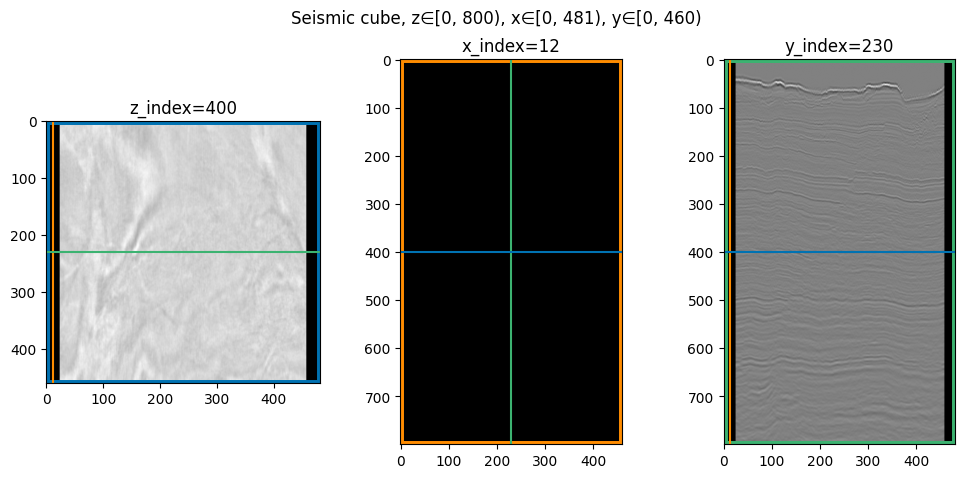

In [3]:
# Куб с пропусками в трех проекциях
SeismicUtils.visualize_three_plots(cube=cube, z_index=400, x_index=12, y_index=230)

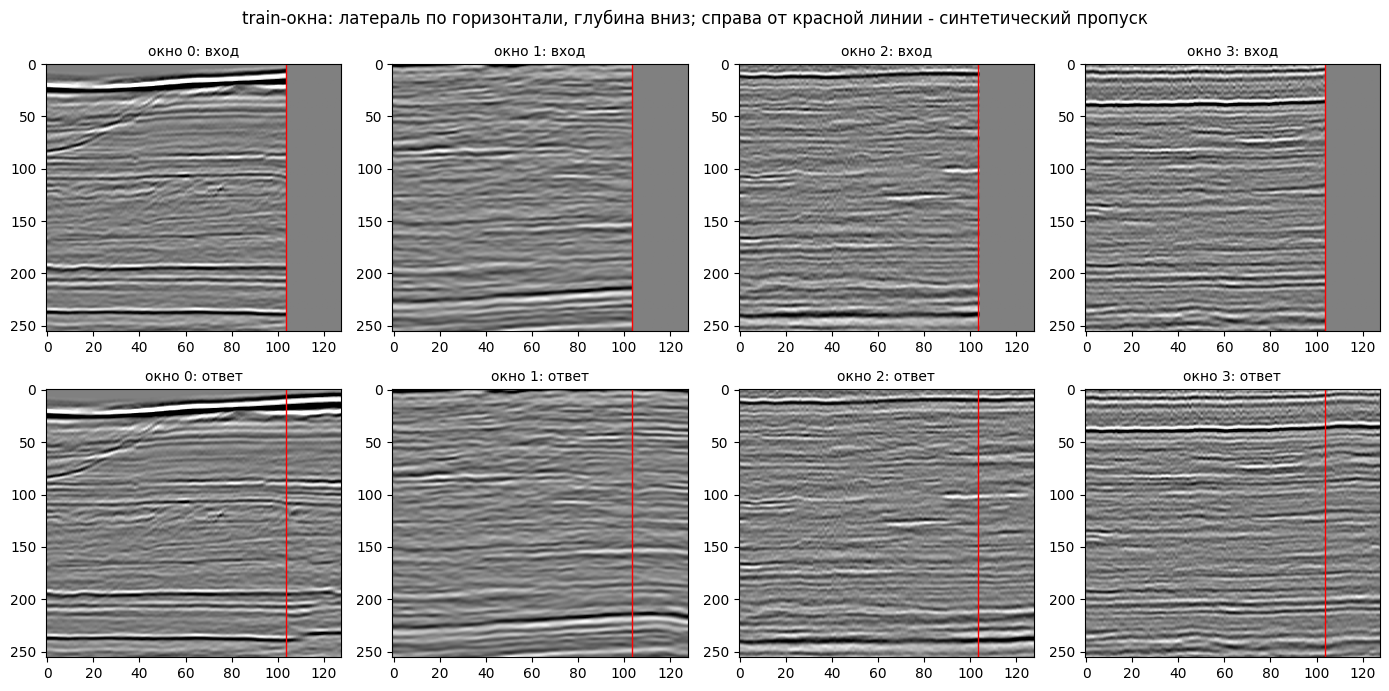

In [4]:
# Примеры обучающих окон: вход (центральный срез, пропуск обнулен) и ответ
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for c in range(4):
    x, y, m = train_ds[c]
    k = CFG['k']
    for r, (img, t) in enumerate([(x[k // 2], 'вход'), (y[0], 'ответ')]):
        ax[r, c].imshow(img.numpy().T, cmap='gray', vmin=-2.5, vmax=2.5, aspect='auto')
        ax[r, c].axvline(CFG['width'] - CFG['edge'] - .5, color='r', lw=1)
        ax[r, c].set_title(f'окно {c}: {t}', fontsize=10)
fig.suptitle('train-окна: латераль по горизонтали, глубина вниз; справа от красной линии - синтетический пропуск')
plt.tight_layout()
plt.show()

## Модель

**U-Net**, 4 уровня энкодера, base = 32 канала, блоки DoubleConv (Conv3×3–BN–ReLU × 2), ~8.6 млн параметров.
- **Вход** — 6 каналов: 5 соседних срезов с обнуленным пропуском и маска пропуска.
- **Выход** — 1 канал: центральный срез целиком. Задача решается как регрессия значений.
- **Итоговая заливка:** известные значения берутся из входа без изменений, из выхода модели только пропуск.
- **Декодер:** билинейный апсемплинг ×2 + свертка 3×3 вместо ConvTranspose2d, чтобы не было шахматных артефактов.

Выбор сделан по val R среди вариантов: U-Net с ConvTranspose (k = 1), с апсемплингом (k = 1), с апсемплингом и 2.5D (k = 5) и GAN (pix2pix) поверх U-Net. У 2.5D-варианта лучший val R (0.578 против 0.561-0.566). Его заливка менее бледная, полос вдоль axis0 нет. Полное сравнение в README репозитория https://github.com/Sofredsun/cv_seysmorazvedka

In [5]:
class DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UpConv(nn.Module):
    """Билинейный апсемплинг x2 + свертка 3x3."""

    def __init__(self, cin, cout):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, 3, padding=1)

    def forward(self, x):
        return self.conv(F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False))


class UNet(nn.Module):
    def __init__(self, in_ch=CFG['k'] + 1, base=CFG['base'], depth=4, up_mode=CFG['up_mode']):
        super().__init__()
        chs = [base * 2 ** i for i in range(depth + 1)]
        self.downs = nn.ModuleList()
        c = in_ch
        for ch in chs[:-1]:
            self.downs.append(DoubleConv(c, ch))
            c = ch
        self.bottleneck = DoubleConv(chs[-2], chs[-1])
        self.ups, self.decs = nn.ModuleList(), nn.ModuleList()
        for ch in reversed(chs[:-1]):
            self.ups.append(nn.ConvTranspose2d(ch * 2, ch, 2, stride=2) if up_mode == 'transpose'
                            else UpConv(ch * 2, ch))
            self.decs.append(DoubleConv(ch * 2, ch))
        self.head = nn.Conv2d(chs[0], 1, 1)
        self.mult = 2 ** depth

    def forward(self, x):
        H, W = x.shape[-2:]
        ph, pw = (-H) % self.mult, (-W) % self.mult
        if ph or pw:
            x = F.pad(x, (0, pw, 0, ph), mode='reflect')
        skips = []
        for d in self.downs:
            x = d(x)
            skips.append(x)
            x = F.max_pool2d(x, 2)
        x = self.bottleneck(x)
        for up, dec, s in zip(self.ups, self.decs, reversed(skips)):
            x = dec(torch.cat([up(x), s], 1))
        return self.head(x)[..., :H, :W]


def composite(known, pred, m):
    return known * (1 - m) + pred * m


def load_model(path):
    ck = torch.load(path, map_location=DEVICE)
    model = UNet(in_ch=ck['k'] + 1, base=ck['base'], up_mode=ck['up_mode']).to(DEVICE)
    model.load_state_dict(ck['state_dict'])
    model.eval()
    return model, ck


print(f"параметров: {sum(p.numel() for p in UNet().parameters()) / 1e6:.2f} млн")

параметров: 8.63 млн


## Обучение модели

**Loss** — по пропуску: L1 + 0.5 · L1 разницы градиентов по глубине и по латерали. Градиентная часть удерживает слоистость

**Метрики** — R (корреляция Пирсона) по пропуску, в двух вариантах:
- **R_mean** — R внутри каждого пропуска, усредненный по окнам;
- **R_global** — один R по всем вокселам всех пропусков

**Оптимизация:**
- AdamW, lr = 1e-3, weight decay = 1e-4;
- OneCycleLR на 40 эпох, batch 16;
- fp32 — в fp16 на GTX 1660 Ti получались NaN.

**Две модели одной конфигурации:**
1. **holdout** — обучается на train-блоке. Лучшая эпоха выбирается по val R, по ней же выбирался вариант модели. Ее test R — честная оценка качества.
2. **финальная** — та же конфигурация и те же 40 эпох, но train — все строки axis0, сохраняется последняя эпоха. Так больше данных и тот же режим обучения. Ее «val» пересекается с train, это только контроль сходимости.

In [6]:
def pearson_r_torch(pred, target, m, eps=1e-6):
    """R по маске для каждого элемента батча -> (B,)."""
    m, p, t = m.flatten(1), pred.flatten(1), target.flatten(1)
    n = m.sum(1).clamp_min(1)
    pc = (p - ((p * m).sum(1) / n)[:, None]) * m
    tc = (t - ((t * m).sum(1) / n)[:, None]) * m
    return (pc * tc).sum(1) / (torch.sqrt((pc ** 2).sum(1) * (tc ** 2).sum(1)) + eps)


class HoleLoss(nn.Module):
    def __init__(self, w_g=CFG['w_grad']):
        super().__init__()
        self.w_g = w_g

    def forward(self, pred, tgt, m):
        n = m.sum().clamp_min(1)
        l1 = ((pred - tgt).abs() * m).sum() / n
        gz = ((torch.diff(pred, dim=-1) - torch.diff(tgt, dim=-1)).abs() * m[..., 1:]).sum() / n
        gx = ((torch.diff(pred, dim=-2) - torch.diff(tgt, dim=-2)).abs() * m[..., 1:, :]).sum() / n
        with torch.no_grad():
            r = pearson_r_torch(pred, tgt, m).mean()
        return l1 + self.w_g * (gz + gx), r.item()


class RAcc:
    """R_mean (по окнам) и R_global (по всем вокселам пропусков) - потоково."""

    def __init__(self):
        self.rs, self.s = [], np.zeros(6)  # n, Σp, Σt, Σp², Σt², Σpt

    def add(self, p, y, m):
        self.rs.append(pearson_r_torch(p, y, m).cpu())
        sel = m > 0.5
        pv, tv = p[sel].double(), y[sel].double()
        self.s += torch.stack([pv.new_tensor(pv.numel()), pv.sum(), tv.sum(), (pv * pv).sum(),
                               (tv * tv).sum(), (pv * tv).sum()]).cpu().numpy()

    def result(self):
        n, sp, st, spp, stt, spt = self.s
        rg = (spt - sp * st / n) / (np.sqrt((spp - sp * sp / n) * (stt - st * st / n)) + 1e-12)
        return float(torch.cat(self.rs).mean()), float(rg)


@torch.no_grad()
def evaluate(model, loader, crit):
    model.eval()
    tot, acc = 0.0, RAcc()
    for x, y, m in loader:
        x, y, m = x.to(DEVICE), y.to(DEVICE), m.to(DEVICE)
        p = model(x)
        tot += crit(p, y, m)[0].item() * x.size(0)
        acc.add(p, y, m)
    model.train()
    return (tot / len(loader.dataset), *acc.result())


def train_model(full, out_path):
    """full=False: train-блок, сохраняется лучшая по val R эпоха; full=True: все строки, последняя эпоха."""
    seed_everything(SEED)
    tr_ds, va_ds, _ = make_datasets(full=full)
    tr = DataLoader(tr_ds, batch_size=CFG['bs'])
    va = DataLoader(va_ds, batch_size=CFG['bs'])
    model = UNet().to(DEVICE)
    crit = HoleLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG['lr'], total_steps=CFG['epochs'] * len(tr))
    meta = {'base': CFG['base'], 'k': CFG['k'], 'stride': CFG['stride'], 'up_mode': CFG['up_mode'],
            'norm': [norm.mean, norm.std], 'full': full}
    vk = 'ctrl' if full else 'val'
    hist = {'train_loss': [], 'train_r': [], f'{vk}_loss': [], f'{vk}_r': [], f'{vk}_r_global': []}
    best, best_ep = -1.0, None
    for ep in range(1, CFG['epochs'] + 1):
        t0, tl, trs = time.time(), 0.0, []
        for x, y, m in tr:
            x, y, m = x.to(DEVICE), y.to(DEVICE), m.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss, r = crit(model(x), y, m)
            loss.backward()
            opt.step()
            sched.step()
            tl += loss.item() * x.size(0)
            trs.append(r)
        vl, vr, vrg = evaluate(model, va, crit)
        for key, v in [('train_loss', tl / len(tr_ds)), ('train_r', float(np.mean(trs))),
                       (f'{vk}_loss', vl), (f'{vk}_r', vr), (f'{vk}_r_global', vrg)]:
            hist[key].append(v)
        if not full and vr > best:
            best, best_ep = vr, ep
            torch.save({'state_dict': model.state_dict(), 'epoch': ep, **meta}, out_path)
        print(f'ep {ep:3d} train {hist["train_loss"][-1]:.4f} r {hist["train_r"][-1]:.4f} | '
              f'{vk} {vl:.4f} r {vr:.4f} rg {vrg:.4f} | {time.time() - t0:.0f}s', flush=True)
    if full:
        torch.save({'state_dict': model.state_dict(), 'epoch': CFG['epochs'], **meta}, out_path)
    return {'hist': hist, 'best_epoch': best_ep}


if RETRAIN:
    MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
    history = {'holdout': train_model(full=False, out_path=HOLDOUT_MODEL_PATH),
               'full': train_model(full=True, out_path=MODEL_PATH)}
    json.dump(history, open(HISTORY_PATH, 'w'), indent=1)
else:
    history = json.load(open(HISTORY_PATH))
print('лучшая эпоха holdout-модели по val R:', history['holdout']['best_epoch'])

лучшая эпоха holdout-модели по val R: 35


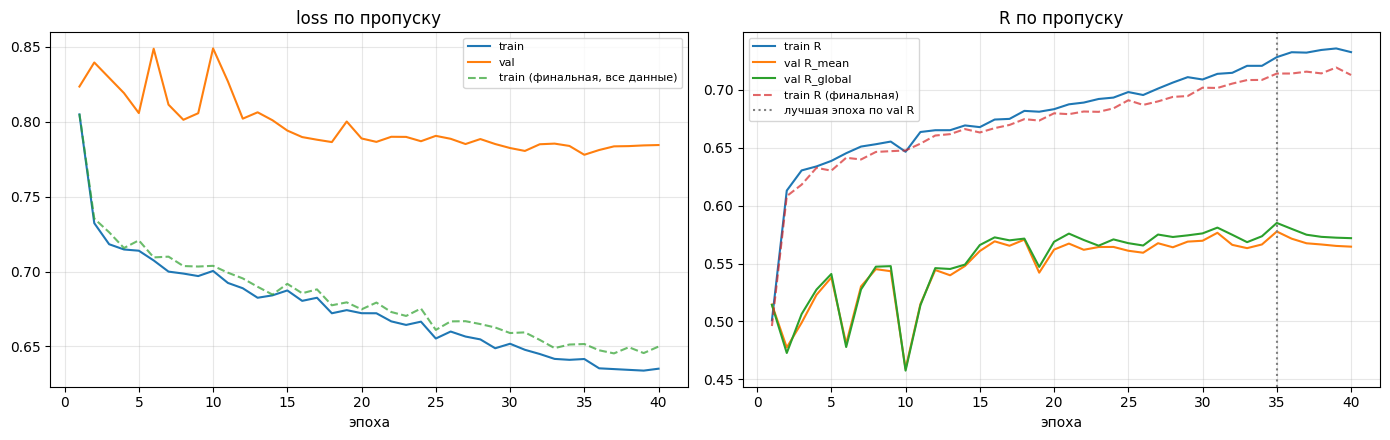

In [7]:
# Графики обучения: train + val по loss и R
h, hf = history['holdout']['hist'], history['full']['hist']
ep = np.arange(1, len(h['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(ep, h['train_loss'], label='train')
ax[0].plot(ep, h['val_loss'], label='val')
ax[0].plot(ep, hf['train_loss'], '--', alpha=.7, label='train (финальная, все данные)')
ax[1].plot(ep, h['train_r'], label='train R')
ax[1].plot(ep, h['val_r'], label='val R_mean')
ax[1].plot(ep, h['val_r_global'], label='val R_global')
ax[1].plot(ep, hf['train_r'], '--', alpha=.7, label='train R (финальная)')
ax[1].axvline(history['holdout']['best_epoch'], color='gray', ls=':', label='лучшая эпоха по val R')
ax[0].set_title('loss по пропуску')
ax[1].set_title('R по пропуску')
for a in ax:
    a.set_xlabel('эпоха')
    a.grid(alpha=.3)
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

В первые 20 эпох модель заметно улучшает качество на валидации. Затем валидационный loss меняется мало, а средний Пирсон колеблется примерно в пределах от 0,55 до 0,58. При этом train loss продолжает снижаться, а Пирсон на обучении растет до 0,73. Разрыв между train и val показывает, что после выхода на плато улучшение на обучающих патчах лишь частично переносится на новые пропуски

Для тестирования выбран чекпойнт 35-й эпохи, на которой получен лучший средний Пирсон на валидации: R_mean = 0,578, R_global = 0,585. На 400 тестовых пропусках с TTA этот чекпойнт показал R_mean = 0,6156 и R_global = 0,6019. Для восстановления реального пропуска использовалась отдельная модель той же архитектуры, обученная 40 эпох на всех известных данных куба

In [8]:
# Лог обучения по эпохам (из сохраненной истории; при RETRAIN = True он же печатается во время обучения)
def print_log(hist, vk, best=None):
    print(f"{'эп':>3} | {'train loss':>10} {'train R':>8} | {vk + ' loss':>10} {vk + ' R':>8} {vk + ' R_gl':>10}")
    for i in range(len(hist['train_loss'])):
        mark = '  <- лучшая по val R' if best == i + 1 else ''
        print(f"{i + 1:>3} | {hist['train_loss'][i]:>10.4f} {hist['train_r'][i]:>8.4f} | "
              f"{hist[vk + '_loss'][i]:>10.4f} {hist[vk + '_r'][i]:>8.4f} {hist[vk + '_r_global'][i]:>10.4f}{mark}")


print('holdout-модель: train - строки 0-319, val - строки 336-395')
print_log(history['holdout']['hist'], 'val', history['holdout']['best_epoch'])
print()
print('финальная модель: train - все строки; ctrl = val-строки, они входят в train -> только контроль сходимости')
print_log(history['full']['hist'], 'ctrl')

holdout-модель: train - строки 0-319, val - строки 336-395
 эп | train loss  train R |   val loss    val R   val R_gl
  1 |     0.8049   0.5011 |     0.8235   0.5147     0.5143
  2 |     0.7323   0.6130 |     0.8396   0.4776     0.4728
  3 |     0.7182   0.6304 |     0.8294   0.4989     0.5064
  4 |     0.7147   0.6339 |     0.8192   0.5230     0.5275
  5 |     0.7139   0.6387 |     0.8058   0.5379     0.5410
  6 |     0.7074   0.6453 |     0.8488   0.4809     0.4780
  7 |     0.6999   0.6511 |     0.8114   0.5303     0.5277
  8 |     0.6986   0.6531 |     0.8013   0.5452     0.5473
  9 |     0.6970   0.6554 |     0.8057   0.5434     0.5478
 10 |     0.7004   0.6466 |     0.8490   0.4592     0.4576
 11 |     0.6924   0.6636 |     0.8269   0.5151     0.5141
 12 |     0.6888   0.6652 |     0.8021   0.5444     0.5461
 13 |     0.6825   0.6652 |     0.8063   0.5399     0.5454
 14 |     0.6841   0.6693 |     0.8010   0.5479     0.5491
 15 |     0.6874   0.6678 |     0.7941   0.5608     0.56

## Тестирование модели

**Test-блок:** строки axis0 400-459, 400 фиксированных окон с синтетическим пропуском. Ни в обучении, ни в выборе модели он не участвовал. Оценивается holdout-модель.

**TTA** — усреднение с предсказанием по стопке соседних срезов в обратном порядке. Флип латерали здесь не применяется: пропуск при нем оказался бы с другой стороны окна.

**Бейзлайн без обучения** — копия последней известной трассы в пропуск.

In [9]:
@torch.no_grad()
def predict(model, x, tta=True):
    k = CFG['k']
    preds = [model(x)]
    if tta:
        preds.append(model(torch.cat([x[:, :k].flip(1), x[:, k:]], 1)))
    return torch.stack(preds).mean(0)


def baseline_nearest(y, m):
    """Копия последней известной трассы в скрытую полосу (справа)."""
    out = y.clone()
    e = int(m[0, 0, :, 0].sum())
    out[:, :, -e:, :] = y[:, :, -e - 1:-e, :]
    return out


test_loader = DataLoader(test_ds, batch_size=CFG['bs'])
holdout, ck_h = load_model(HOLDOUT_MODEL_PATH)
print('holdout-модель: эпоха', ck_h['epoch'])

accs = {'бейзлайн (копия края)': RAcc(), 'U-Net': RAcc(), 'U-Net + TTA': RAcc()}
for x, y, m in test_loader:
    accs['бейзлайн (копия края)'].add(baseline_nearest(y, m), y, m)
    x, y, m = x.to(DEVICE), y.to(DEVICE), m.to(DEVICE)
    accs['U-Net'].add(predict(holdout, x, tta=False), y, m)
    accs['U-Net + TTA'].add(predict(holdout, x, tta=True), y, m)

test_results = {name: dict(zip(['R_mean', 'R_global'], a.result())) for name, a in accs.items()}
print(f"{'модель':<24}{'R_mean':>8}{'R_global':>10}")
for name, r in test_results.items():
    print(f"{name:<24}{r['R_mean']:>8.4f}{r['R_global']:>10.4f}")

holdout-модель: эпоха 35
модель                    R_mean  R_global
бейзлайн (копия края)     0.4734    0.4667
U-Net                     0.6131    0.5995
U-Net + TTA               0.6156    0.6019


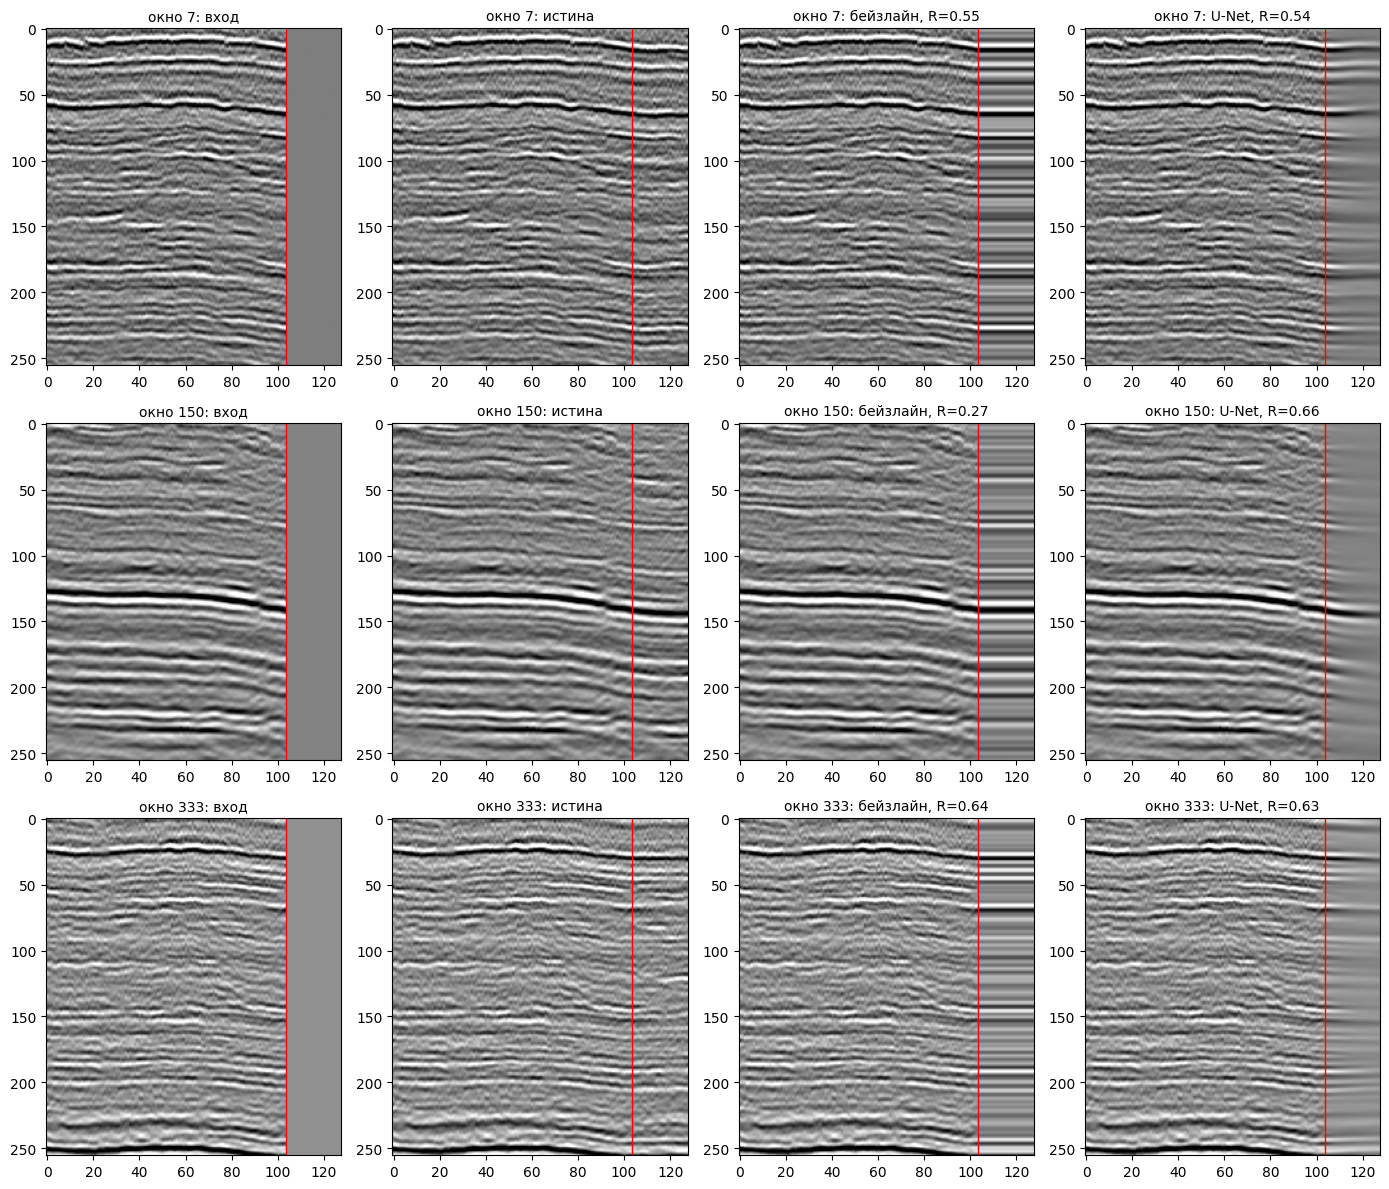

In [10]:
# Примеры с test-блока: вход / истина / бейзлайн / U-Net
idxs = [7, 150, 333]
fig, ax = plt.subplots(len(idxs), 4, figsize=(14, 4 * len(idxs)))
for row, i in enumerate(idxs):
    x, y, m = (t[None] for t in test_ds[i])
    p = composite(y, predict(holdout, x.to(DEVICE)).cpu(), m)
    b = baseline_nearest(y, m)
    lo, hi = np.percentile(y.numpy(), [1, 99])
    panels = [((y * (1 - m))[0, 0], 'вход'), (y[0, 0], 'истина'),
              (b[0, 0], f'бейзлайн, R={pearson_r_torch(b, y, m).item():.2f}'),
              (p[0, 0], f'U-Net, R={pearson_r_torch(p, y, m).item():.2f}')]
    for c, (img, title) in enumerate(panels):
        ax[row, c].imshow(img.numpy().T, cmap='gray', vmin=lo, vmax=hi, aspect='auto')
        ax[row, c].axvline(CFG['width'] - CFG['edge'] - .5, color='r', lw=1)
        ax[row, c].set_title(f'окно {i}: {title}', fontsize=10)
plt.tight_layout()
plt.show()

**Итог на test:**
- U-Net заметно лучше бейзлайна: R_global ≈ 0.60 против 0.47.
- Слоистость продолжается в пропуск, но с удалением от края данных заливка бледнеет. Модель обучена с L1 и предсказывает «условное среднее», амплитуда занижена, std заливки ≈ 0.7 от данных.

## Инференс модели

Используется **финальная модель**. Для каждого из 460 срезов axis0 повторяется то же, что на обучении:
1. **Правый край:** окно [:, 353:481, :] на всю глубину 800, пропуск — последние 24 трассы окна.
2. **Левый край:** окно [:, 0:128, :] зеркально переворачивается по axis1, чтобы пропуск оказался справа. После предсказания результат переворачивается обратно.
3. На вход подается стопка из 5 соседних срезов по axis0, у границ куба — с отражением. Применяется TTA с флипом стопки.
4. Предсказание переводится обратно из нормированных единиц и вставляется только в пропуск. Известные значения куба не меняются.

In [11]:
@torch.no_grad()
def predict_windows(model, stacks, m, bs=8):
    """stacks: (N, k, H, W) нормированные стопки, m: (H, W) маска -> (N, H, W)."""
    out = np.empty((stacks.shape[0],) + stacks.shape[2:], dtype=np.float32)
    mt = torch.from_numpy(m.astype(np.float32)).to(DEVICE)
    for s in range(0, stacks.shape[0], bs):
        xs = torch.from_numpy(np.ascontiguousarray(stacks[s:s + bs])).to(DEVICE)
        mm = mt.expand(xs.shape[0], 1, *mt.shape)
        preds = [model(torch.cat([xs * (1 - mt), mm], 1)),
                 model(torch.cat([xs.flip(1) * (1 - mt), mm], 1))]   # TTA: флип стопки
        out[s:s + bs] = torch.stack(preds).mean(0)[:, 0].cpu().numpy()
    return out


def stacks_axis0(cube_n, offs, js):
    """Для каждого среза i: стопка соседей по axis0 (с отражением у границ) в окне js -> (N, k, W, Z)."""
    n0 = cube_n.shape[0]
    idx = np.arange(n0)[:, None] + offs[None]
    idx = np.where(idx < 0, -idx, idx)
    idx = np.where(idx >= n0, 2 * (n0 - 1) - idx, idx)
    return cube_n[:, js, :][idx]


def restore_cube(cube, model, ck, width=CFG['width']):
    m_cube = hole_mask(cube.shape)
    offs = neighbor_offsets(ck['k'], ck['stride'])
    nrm = Norm(*ck['norm'])
    cube_n = nrm.fwd(cube.astype(np.float32))
    restored = cube.copy()
    n1 = cube.shape[1]
    # Правый край
    js = slice(n1 - width, n1)
    m = m_cube[0, js, :]
    pred = predict_windows(model, stacks_axis0(cube_n, offs, js), m)
    restored[:, js, :][:, m] = nrm.inv(pred[:, m])
    # Левый край: зеркально по axis1 -> пропуск справа
    js = slice(0, width)
    m = m_cube[0, js, :][::-1]
    pred = predict_windows(model, stacks_axis0(cube_n, offs, js)[:, :, ::-1], m)[:, ::-1]
    restored[:, js, :][:, m[::-1]] = nrm.inv(pred[:, m[::-1]])
    return restored


final_model, ck_f = load_model(MODEL_PATH)
print('финальная модель:', {k: v for k, v in ck_f.items() if k != 'state_dict'})
t0 = time.time()
restored = restore_cube(cube, final_model, ck_f)
print(f'инференс {time.time() - t0:.0f} с')

финальная модель: {'epoch': 40, 'base': 32, 'k': 5, 'stride': 2, 'up_mode': 'upsample', 'norm': [0.4999515116214752, 0.02933446504175663], 'full': True}
инференс 35 с


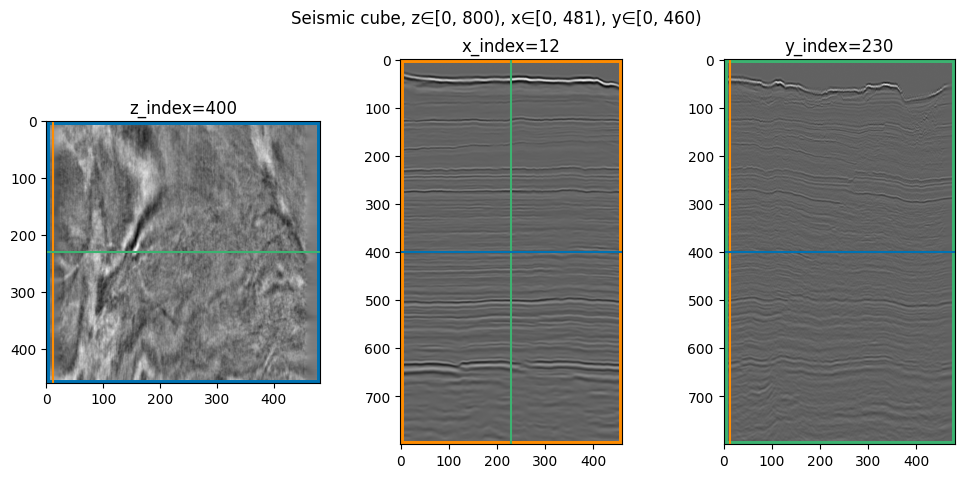

In [12]:
SeismicUtils.visualize_three_plots(cube=restored, z_index=400, x_index=12, y_index=230)

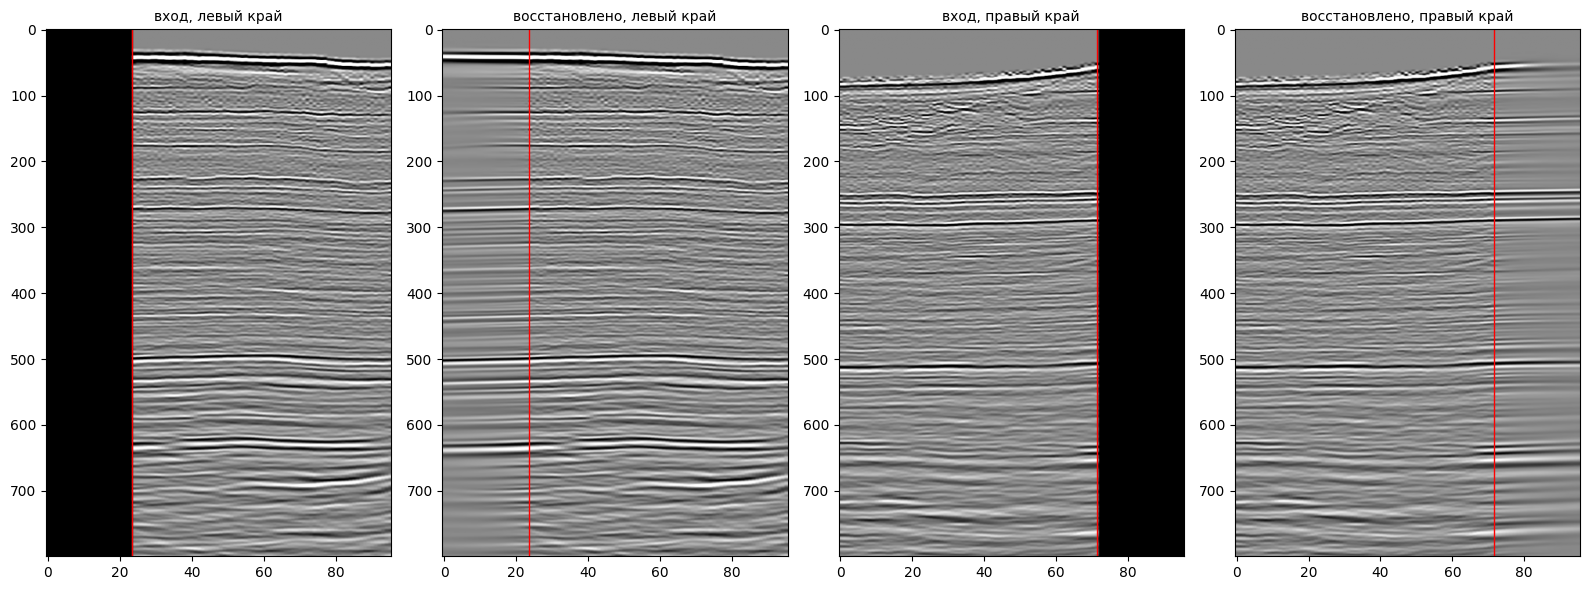

In [13]:
# Края крупно: срез axis0=230, крайние 96 трасс (красная линия - граница пропуска)
i0, w, e = 230, 96, CFG['edge']
lo, hi = np.percentile(cube[i0][~mask[i0]], [1, 99])
n1 = cube.shape[1]
parts = [(cube[i0, :w], 'вход, левый край', e), (restored[i0, :w], 'восстановлено, левый край', e),
         (cube[i0, n1 - w:], 'вход, правый край', w - e), (restored[i0, n1 - w:], 'восстановлено, правый край', w - e)]
fig, ax = plt.subplots(1, 4, figsize=(16, 6))
for a, (img, title, line) in zip(ax, parts):
    a.imshow(img.T, cmap='gray', vmin=lo, vmax=hi, aspect='auto')
    a.axvline(line - .5, color='r', lw=1)
    a.set_title(title, fontsize=10)
plt.tight_layout()
plt.show()

## Блок сохранения артефактов

- **Модель.** Веса сохраняются через torch.save в словаре вместе с конфигурацией (k, stride, base, up_mode) и параметрами нормировки (norm). Этого достаточно, чтобы восстановить модель функцией load_model из блока «Модель». При RETRAIN = True файлы перезаписываются в блоке обучения.
- **Восстановленный куб** сохраняется в .npy, в исходном типе float32 и в исходных единицах.
- **Проверки перед сохранением:** размер совпадает со входом, NaN и inf нет, известные значения не изменены, в пропуске не осталось нулей

In [14]:
assert restored.shape == cube.shape, (restored.shape, cube.shape)
assert restored.dtype == cube.dtype
assert np.isfinite(restored).all(), 'NaN/inf в результате'
assert np.array_equal(restored[~mask], cube[~mask]), 'известные значения изменены'
assert not (restored[mask] == 0).any(), 'в пропуске остались нули'
filled, known = restored[mask], cube[~mask][::97]
print(f'shape {restored.shape} == input {cube.shape}, dtype {restored.dtype}')
print(f'известные данные: mean {known.mean():.4f} std {known.std():.4f} | '
      f'заливка: mean {filled.mean():.4f} std {filled.std():.4f}')

RESTORED_PATH.parent.mkdir(parents=True, exist_ok=True)
np.save(RESTORED_PATH, restored)
print('куб сохранен:', RESTORED_PATH, f'{RESTORED_PATH.stat().st_size / 1e6:.0f} МБ')

print('модель:', MODEL_PATH, f'{MODEL_PATH.stat().st_size / 1e6:.1f} МБ, ключи:', list(ck_f))
reloaded, _ = load_model(MODEL_PATH)
assert all(torch.equal(a, b) for a, b in zip(reloaded.state_dict().values(), final_model.state_dict().values()))
print('модель загружается и совпадает с использованной на инференсе')

shape (460, 481, 800) == input (460, 481, 800), dtype float32
известные данные: mean 0.4999 std 0.0293 | заливка: mean 0.4999 std 0.0202
куб сохранен: results\outpainting_restored.npy 708 МБ
модель: models\outpainting_model.pt 34.6 МБ, ключи: ['state_dict', 'epoch', 'base', 'k', 'stride', 'up_mode', 'norm', 'full']
модель загружается и совпадает с использованной на инференсе
